# Credit Risk Scoring
Imports and setup.

In [79]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

os.makedirs('outputs', exist_ok=True)
sns.set_style('whitegrid')

Load the data and take a first look.

In [80]:
df = pd.read_csv('data/credit_risk_dataset.csv')
print(df.shape)
df.head()

(32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [81]:
print(df['loan_status'].value_counts(normalize=True).round(3))


print(df.isna().sum())
print('duplicates:', df.duplicated().sum())
df.describe().T

loan_status
0    0.782
1    0.218
Name: proportion, dtype: float64
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64
duplicates: 165


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


Clean the data. Remove duplicates and impossible values, then fill the missing values.

In [82]:
df = df.drop_duplicates()

# some values are not possible (age 144, 123 years of work)
print('age > 80:', (df['person_age']>80).sum())
print('emp length > 50:', (df['person_emp_length']>50).sum())
print('income > 1m:', (df['person_income']>1000000).sum())

df = df[df['person_age']<=80]
df=df[(df['person_emp_length'].isna()) | (df['person_emp_length']<=50)]
df = df[df['person_income']<=1000000]

# missing values
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())
df['loan_int_rate'] = df['loan_int_rate'].fillna(df.groupby('loan_grade')['loan_int_rate'].transform('median'))    #rate depends on grade

df = df.reset_index(drop=True)
print(df.shape)
print(df.isna().sum().sum())

age > 80: 7
emp length > 50: 2
income > 1m: 9
(32399, 12)
0


Encode the categorical columns.

In [83]:
# grade has an order, so use numbers (A is best)
grade_map = {'A':1,'B':2,'C':3,'D':4,'E':5,'F':6,'G':7}
df['grade_num'] =df['loan_grade'].map(grade_map)

# credit history flag y/n
df['prev_default'] = (df['cb_person_default_on_file']=='Y').astype(int)

# no order here, so one hot
df = pd.get_dummies(df, columns=['person_home_ownership','loan_intent'], drop_first=True, dtype=int)

df = df.drop(columns=['loan_grade','cb_person_default_on_file'])
print(df.shape)
df.head()

(32399, 18)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,grade_num,prev_default,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,21,9600,5.0,1000,11.14,0,0.10,2,2,0,0,1,0,1,0,0,0,0
1,25,9600,1.0,5500,12.87,1,0.57,3,3,0,0,0,0,0,0,1,0,0
2,23,65500,4.0,35000,15.23,1,0.53,2,3,0,0,0,1,0,0,1,0,0
3,24,54400,8.0,35000,14.27,1,0.55,4,3,1,0,0,1,0,0,1,0,0
4,21,9900,2.0,2500,7.14,1,0.25,2,1,0,0,1,0,0,0,0,0,1


Feature engineering. Debt-to-income and a few other ratios.

In [84]:
df['debt_to_income'] = df['loan_amnt']/df['person_income']
df['interest_cost'] = df['loan_amnt']*df['loan_int_rate']/100        # yearly interest in dollars
df['interest_to_income']=df['interest_cost']/df['person_income']
df['emp_to_age'] = df['person_emp_length']/df['person_age']
df['hist_to_age']=df['cb_person_cred_hist_length']/df['person_age']
df['log_income'] = np.log(df['person_income'])

# check against the given column
print(df[['debt_to_income','loan_percent_income']].corr().round(3))
df[['debt_to_income','interest_to_income','emp_to_age','hist_to_age']].describe().round(3)

                     debt_to_income  loan_percent_income
debt_to_income                1.000                0.999
loan_percent_income           0.999                1.000


,debt_to_income,interest_to_income,emp_to_age,hist_to_age
count,32399.000,32399.000,32399.000,32399.000
mean,0.171,0.019,0.173,0.195
std,0.107,0.014,0.134,0.094
min,0.001,0.000,0.000,0.077
25%,0.090,0.009,0.067,0.125
50%,0.148,0.015,0.148,0.174
75%,0.229,0.026,0.273,0.262
max,0.830,0.115,0.717,0.588


Split the data and set up three models to compare.

In [85]:
y = df['loan_status']
X = df.drop(columns=['loan_status'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)}

(25919, 23) (6480, 23)


5-fold cross-validation on the training data. The target is AUC above 0.85.

In [86]:
skf = StratifiedKFold(5, shuffle=True, random_state=42)
res = {}

for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=skf, scoring='roc_auc')
    res[name] = s
    print(name, '-> AUC', round(s.mean(),3), '+/-', round(s.std(),3))

best_name = max(res, key=lambda k: res[k].mean())
print('best model:', best_name)
print('target AUC > 0.85 met:', res[best_name].mean() > 0.85)

Logistic Regression -> AUC 0.88 +/- 0.007
Random Forest -> AUC 0.932 +/- 0.004
Gradient Boosting -> AUC 0.928 +/- 0.003
best model: Random Forest
target AUC > 0.85 met: True


Fit the best model and check it on the test set.

In [87]:
best = models[best_name]
best.fit(X_train, y_train)

probs = best.predict_proba(X_test)[:,1]
pred = (probs>=0.5).astype(int)

print('test AUC:', round(roc_auc_score(y_test, probs),3))
print(classification_report(y_test, pred))

test AUC: 0.938
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5062
           1       0.96      0.73      0.83      1418

    accuracy                           0.93      6480
   macro avg       0.95      0.86      0.89      6480
weighted avg       0.94      0.93      0.93      6480



ROC curves for all models.

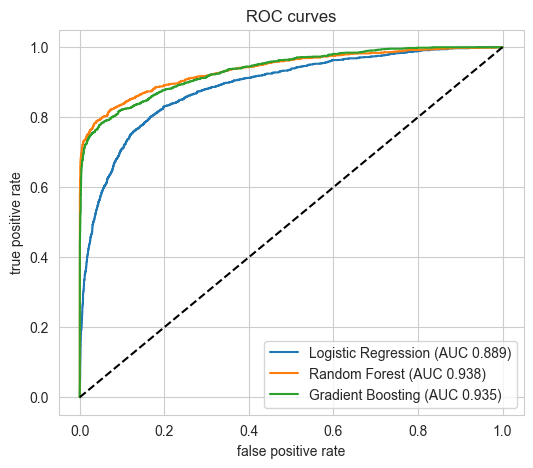

In [88]:
plt.figure(figsize=(6,5))
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:,1]
    fpr,tpr,_ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=name+' (AUC '+str(round(roc_auc_score(y_test,p),3))+')')

plt.plot([0,1],[0,1],'k--')
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title('ROC curves')
plt.legend()
plt.savefig('outputs/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

Confusion matrix and feature importance.

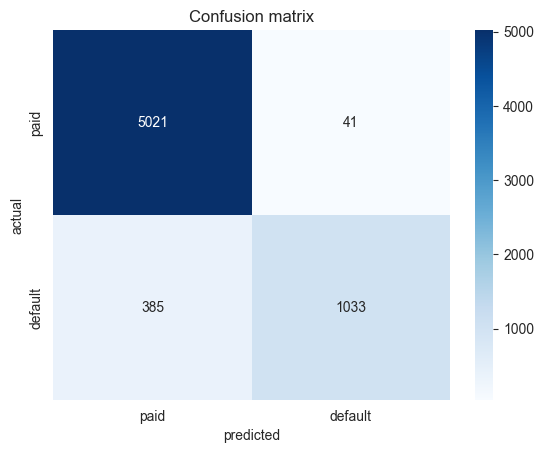

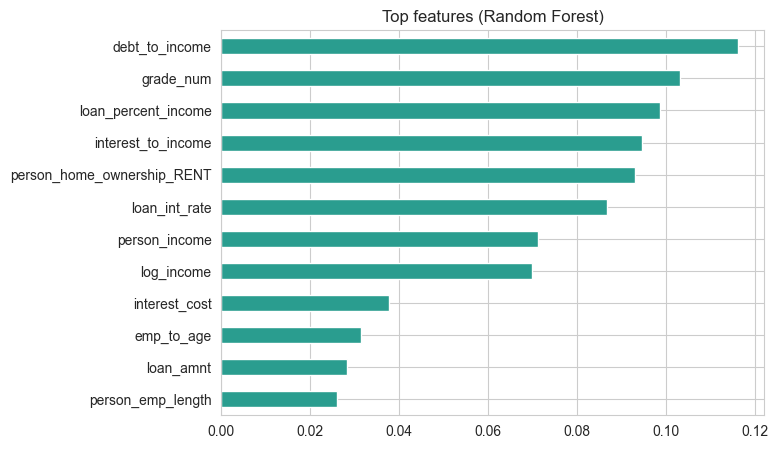

In [89]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['paid','default'], yticklabels=['paid','default'])
plt.title('Confusion matrix')
plt.xlabel('predicted'); plt.ylabel('actual')
plt.savefig('outputs/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


# feature importance
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(12)
imp.plot(kind='barh', figsize=(7,5), color='#2a9d8f')
plt.title('Top features (Random Forest)')
plt.savefig('outputs/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

Credit risk scoring system. Each customer gets a score from 0 to 100, where higher is safer. Scores come from out-of-fold predictions, so the model never scores a customer it trained on.

In [90]:
# out of fold probabilities so every customer gets an honest score
df['default_prob'] = cross_val_predict(best, X, y, cv=skf, method='predict_proba')[:,1]

# 0 to 100, higher = safer
df['credit_score'] = ((1-df['default_prob'])*100).round(1)

bands = [0,40,60,80,100.01]
labels = ['Very high risk','High risk','Medium risk','Low risk']
df['risk_band'] = pd.cut(df['credit_score'], bins=bands, labels=labels, right=False)

band_tbl = df.groupby('risk_band', observed=True).agg(
    customers=('loan_status','count'),
    default_rate=('loan_status','mean'),
    avg_score=('credit_score','mean')).round(3)
print(band_tbl)
print('overall auc of score:', round(roc_auc_score(y, -df['credit_score']),3))

                customers  default_rate  avg_score
risk_band                                         
Very high risk       4871         0.983      9.796
High risk             929         0.498     50.823
Medium risk          2985         0.228     72.488
Low risk            23614         0.049     93.631
overall auc of score: 0.935


Check that the score works. Defaulters should have low scores.

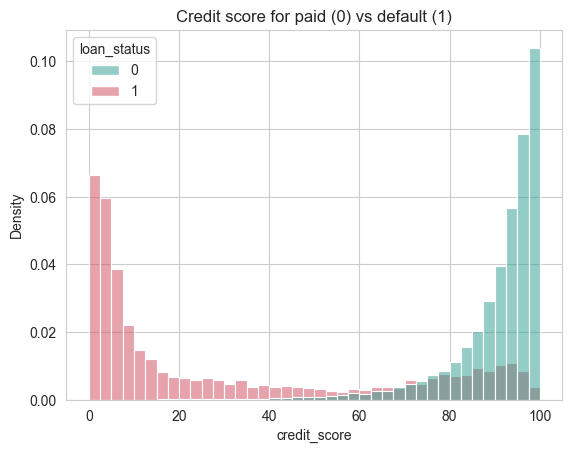

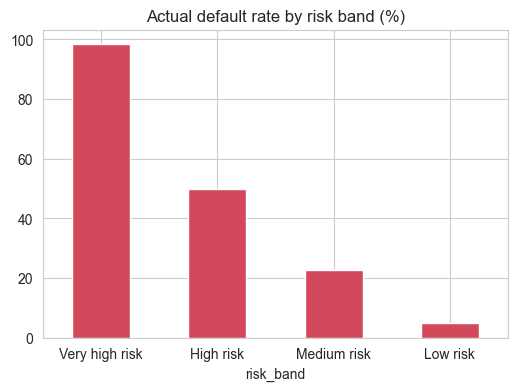

In [91]:
sns.histplot(data=df, x='credit_score', hue='loan_status', bins=40, stat='density', common_norm=False, palette={0:'#2a9d8f',1:'#d1495b'})
plt.title('Credit score for paid (0) vs default (1)')
plt.savefig('outputs/score_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


band_tbl['default_rate'].mul(100).plot(kind='bar', color='#d1495b', figsize=(6,4))
plt.title('Actual default rate by risk band (%)')
plt.xticks(rotation=0)
plt.savefig('outputs/default_rate_by_band.png', dpi=150, bbox_inches='tight')
plt.show()